In [1]:
# This code calculates the predicted association scores using collaborative filtering technique
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sn
from sklearn.metrics import accuracy_score
import scipy as sp
from tqdm import tqdm
import random

from pathlib import Path

In [2]:
# random seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

In [3]:
# directories
ROOT_OUT = Path("leakage_free_70_30")
SPLIT_DIR = ROOT_OUT / "data_split"
GIP_DIR = ROOT_OUT / "GIP_similarities"
INTEGRATED_DIR = ROOT_OUT / "integrated_similarities"
CF_DIR = ROOT_OUT / "CF_scores"

CF_DIR.mkdir(parents=True, exist_ok=True)

In [4]:
# reading data sets associations, mirna names and disease names respectively
m_d_associations = pd.read_csv('datasets/1.miRNA_disease_association/miRNA-disease-association-data.csv', header=0, names=["MiRNA", "Disease"])
disease_names = pd.read_csv('datasets/1.miRNA_disease_association/disease name.csv', header=None)
mirna_names = pd.read_csv('datasets/1.miRNA_disease_association/miRNA name.csv', header=None)

In [5]:
m_d_associations.shape, disease_names.shape, mirna_names.shape

((5430, 2), (383, 2), (495, 2))

In [6]:

# importing adjacency matrix and integrated mirna and disease features

# A = Adjacency matrix, SM = integrated mirna features, SD = integrated disease features
nm = len(mirna_names)
nd = len(disease_names)

A = np.loadtxt(SPLIT_DIR / "adjacency_matrix_train_70.txt")
SM = np.loadtxt(INTEGRATED_DIR / "mirna_integrated_similarity_train.txt")
SD = np.loadtxt(INTEGRATED_DIR / "disease_integrated_similarity_train.txt")
train_positive_pairs = pd.read_csv(SPLIT_DIR / "train_positive_pairs.csv")
heldout_positive_pairs = pd.read_csv(SPLIT_DIR / "heldout_positive_pairs.csv")


In [7]:
# sanity checks
print("A_train shape:", A.shape)
print("SM_train shape:", SM.shape)
print("SD_train shape:", SD.shape)

print("Training positives:", len(train_positive_pairs))
print("Held-out positives:", len(heldout_positive_pairs))
print("Associations in A_train:", int(A.sum()))

assert A.shape == (nm, nd)
assert SM.shape == (nm, nm)
assert SD.shape == (nd, nd)

assert int(A.sum()) == len(train_positive_pairs)

for m, d in heldout_positive_pairs.itertuples(index=False):
    assert A[int(m)-1, int(d)-1] == 0

print("All held-out positive associations are absent from A_train.")

A_train shape: (495, 383)
SM_train shape: (495, 495)
SD_train shape: (383, 383)
Training positives: 3801
Held-out positives: 1629
Associations in A_train: 3801
All held-out positive associations are absent from A_train.


In [8]:
# creating dataframes from matrices
A_df = pd.DataFrame(A, index=range(1, nm+1), columns=range(1, nd+1))
SM_df = pd.DataFrame(SM, index=range(1, nm+1), columns=range(1, nm+1))
SD_df = pd.DataFrame(SD, index=range(1, nd+1), columns=range(1, nd+1))

In [9]:
A.shape, SM.shape, SD.shape

((495, 383), (495, 495), (383, 383))

In [10]:
A_df

,1,2,3,4,5,6,7,8,9,10,...,374,375,376,377,378,379,380,381,382,383
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
491,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
492,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
493,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
494,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


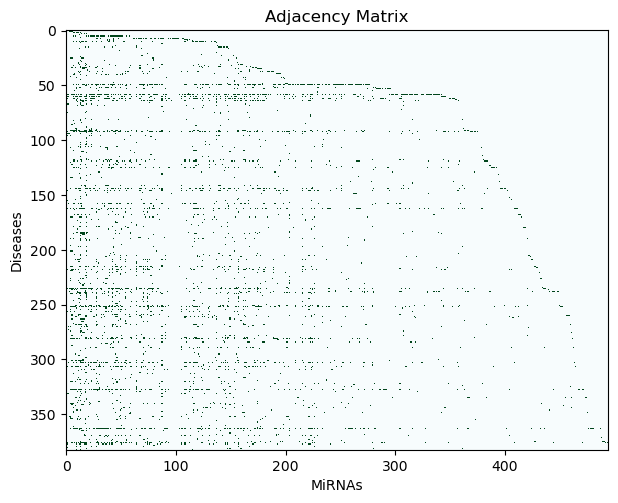

In [11]:
# adjacency matrix A
fig = plt.figure(figsize=(7, 10)) # in inches
plt.title('Adjacency Matrix')
plt.xlabel('MiRNAs')
plt.ylabel('Diseases')
plt.imshow(A_df.T, cmap="BuGn", interpolation="none")

In [12]:
SM_df

,1,2,3,4,5,6,7,8,9,10,...,486,487,488,489,490,491,492,493,494,495
1,1.000000,0.476800,0.064907,0.353500,0.544400,0.482700,0.490000,0.496600,0.476600,0.639200,...,0.084218,0.084218,0.073934,0.073934,0.073934,0.073934,0.073934,0.084218,0.073934,0.073934
2,0.476800,1.000000,0.095932,0.289800,0.402700,0.474700,0.524900,0.326500,0.487100,0.422700,...,0.073934,0.073934,0.064907,0.064907,0.064907,0.064907,0.084218,0.073934,0.084218,0.084218
3,0.064907,0.095932,1.000000,0.183971,0.004799,0.006227,0.007093,0.022900,0.020103,0.005466,...,0.271909,0.271909,0.238707,0.238707,0.238707,0.238707,0.238707,0.271909,0.238707,0.238707
4,0.353500,0.289800,0.183971,1.000000,0.420600,0.417500,0.309400,0.192000,0.221200,0.315800,...,0.521449,0.521449,0.457777,0.457777,0.457777,0.457777,0.457777,0.521449,0.457777,0.457777
5,0.544400,0.402700,0.004799,0.420600,1.000000,0.805400,0.541500,0.438800,0.278600,0.445200,...,0.013602,0.013602,0.015494,0.011941,0.011941,0.011941,0.011941,0.013602,0.011941,0.011941
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
491,0.073934,0.064907,0.238707,0.457777,0.011941,0.015494,0.008079,0.043915,0.050023,0.008079,...,0.877894,0.877894,0.770699,0.770699,1.000000,1.000000,0.770699,0.877894,0.770699,0.770699
492,0.073934,0.084218,0.238707,0.457777,0.011941,0.020103,0.008079,0.056981,0.050023,0.010483,...,0.877894,0.877894,0.770699,0.770699,0.770699,0.770699,1.000000,0.877894,1.000000,0.770699
493,0.084218,0.073934,0.271909,0.521449,0.013602,0.017649,0.009203,0.050023,0.056981,0.009203,...,1.000000,1.000000,0.877894,0.877894,0.877894,0.877894,0.877894,1.000000,0.877894,0.877894
494,0.073934,0.084218,0.238707,0.457777,0.011941,0.020103,0.008079,0.056981,0.050023,0.010483,...,0.877894,0.877894,0.770699,0.770699,0.770699,0.770699,1.000000,0.877894,1.000000,0.770699


In [13]:
SD_df

,1,2,3,4,5,6,7,8,9,10,...,374,375,376,377,378,379,380,381,382,383
1,1.000000,0.038240,0.403787,0.546305,0.668277,0.032519,0.668277,0.032519,0.365083,0.446595,...,0.330089,0.403787,0.163044,0.059719,0.049938,0.604221,0.330089,0.817482,0.403787,0.546305
2,0.038240,1.000000,0.403787,0.546305,0.668277,0.032519,0.668277,0.084313,0.365083,0.446595,...,0.330089,0.403787,0.073187,0.097589,0.121246,0.604221,0.330089,0.668277,0.034299,0.546305
3,0.403787,0.403787,1.000000,0.015619,0.493940,0.152393,0.244850,0.024035,0.188205,0.164830,...,0.243977,0.298449,0.147416,0.066923,0.056765,0.446595,0.365083,0.493940,0.059536,0.604221
4,0.546305,0.546305,0.015619,1.000000,0.668277,0.039779,0.668277,0.032519,0.365083,0.446595,...,0.330089,0.403787,0.163044,0.001750,0.035966,0.604221,0.164015,0.668277,0.098012,0.546305
5,0.668277,0.668277,0.493940,0.668277,1.000000,0.039779,0.817482,0.039779,0.446595,0.546305,...,0.403787,0.493940,0.188323,0.001170,0.035966,0.739125,0.403787,0.817482,0.493940,0.092230
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
379,0.604221,0.604221,0.446595,0.604221,0.739125,0.035966,0.739125,0.043996,0.403787,0.493940,...,0.365083,0.446595,0.180329,0.001057,0.026583,1.000000,0.365083,0.739125,0.446595,0.604221
380,0.330089,0.330089,0.365083,0.164015,0.403787,0.029402,0.493940,0.029402,0.220591,0.269842,...,0.298449,0.243977,0.120510,0.001582,0.026583,0.365083,1.000000,0.403787,0.119578,0.493940
381,0.817482,0.668277,0.493940,0.668277,0.817482,0.039779,0.817482,0.039779,0.446595,0.546305,...,0.403787,0.493940,0.199447,0.001431,0.035966,0.739125,0.403787,1.000000,0.493940,0.668277
382,0.403787,0.034299,0.059536,0.098012,0.493940,0.090869,0.106929,0.024035,0.029568,0.026842,...,0.243977,0.298449,0.120510,0.028992,0.025345,0.446595,0.119578,0.493940,1.000000,0.403787


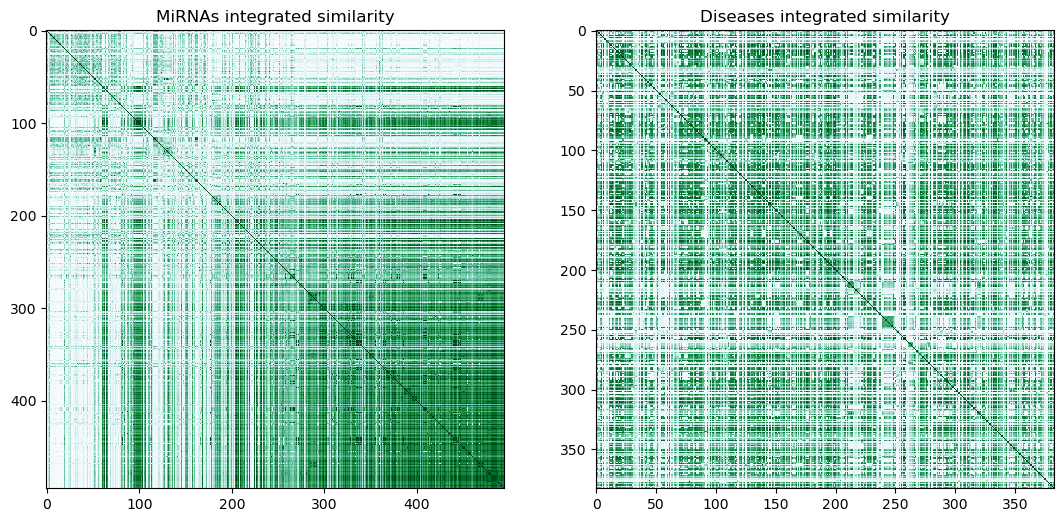

In [14]:
# integrated mirna and disease similarities

fig, (fig1, fig2) = plt.subplots(1, 2, figsize=(13,13))
fig1.title.set_text('MiRNAs integrated similarity')
fig2.title.set_text('Diseases integrated similarity')
fig1.imshow(SM, cmap="BuGn", interpolation="none")
fig2.imshow(SD, cmap="BuGn", interpolation="none")

# Generating features and training the model

In [15]:
from sklearn.metrics.pairwise import cosine_similarity
import random
from sklearn.decomposition import TruncatedSVD

In [16]:
# calculating cosine similarities for collaborative filtering
mirna_similarity_cosine = cosine_similarity(SM)
disease_similarity_cosine = cosine_similarity(SD)

In [17]:
type(mirna_similarity_cosine), type(disease_similarity_cosine)

(numpy.ndarray, numpy.ndarray)

In [18]:
# saving cosine similarities
COSINE_DIR = ROOT_OUT / "cosine_similarities"
COSINE_DIR.mkdir(parents=True, exist_ok=True)

np.savetxt(COSINE_DIR / "mirna_similarity_cosine_train.txt", mirna_similarity_cosine)
np.savetxt(COSINE_DIR / "disease_similarity_cosine_train.txt", disease_similarity_cosine)

In [19]:
# mirna similarity matrix using cosine similarity
print(mirna_similarity_cosine)

[[1.         0.93894282 0.41129579 ... 0.3810546  0.38499235 0.38471716]
 [0.93894282 1.         0.4313213  ... 0.39934453 0.40371656 0.40290048]
 [0.41129579 0.4313213  1.         ... 0.96808715 0.96686595 0.96792988]
 ...
 [0.3810546  0.39934453 0.96808715 ... 1.         0.99868699 0.99965439]
 [0.38499235 0.40371656 0.96686595 ... 0.99868699 1.         0.99833393]
 [0.38471716 0.40290048 0.96792988 ... 0.99965439 0.99833393 1.        ]]


In [20]:
# diseases similarity matrix using cosine similarity
print(disease_similarity_cosine)

[[1.         0.91831506 0.79503309 ... 0.92585263 0.79677413 0.94979967]
 [0.91831506 1.         0.78234973 ... 0.87958533 0.73457328 0.90024327]
 [0.79503309 0.78234973 1.         ... 0.80120146 0.7704885  0.82951341]
 ...
 [0.92585263 0.87958533 0.80120146 ... 1.         0.80121019 0.95310358]
 [0.79677413 0.73457328 0.7704885  ... 0.80121019 1.         0.79156392]
 [0.94979967 0.90024327 0.82951341 ... 0.95310358 0.79156392 1.        ]]


In [21]:
#getting most similar items using cosine similarity

N_VALUES = list(range(5, 101, 5))
SIMILARITY_THRESHOLD = 0.05

def cosineSimilarity(cos_sim_matrix, n):
    similar_items = []
    for current_item in cos_sim_matrix.index:
        # excluding the current item without modifying original matrix
        candidates = cos_sim_matrix.drop(index=current_item)
        similar_i = (
            candidates[candidates[current_item] > SIMILARITY_THRESHOLD][current_item]
            .sort_values(ascending=False)
            .head(n)
        )
        similar_items.append(similar_i)
    return similar_items

In [22]:
#most similar miRNAs and diseases used for candidate generation

CANDIDATE_N = 5
similar_mirnas = cosineSimilarity(
    pd.DataFrame(mirna_similarity_cosine, index=range(1, nm+1), columns=range(1, nm+1)), 
    CANDIDATE_N
)
similar_diseases = cosineSimilarity(
    pd.DataFrame(disease_similarity_cosine, index=range(1, nd+1), columns=range(1, nd+1)),
    CANDIDATE_N
)

In [23]:
display(similar_mirnas), display(similar_diseases)

[24     0.959669
 42     0.952066
 75     0.952047
 138    0.949593
 80     0.948657
 Name: 1, dtype: float64,
 42     0.964245
 121    0.957045
 119    0.947014
 80     0.946403
 15     0.941537
 Name: 2, dtype: float64,
 325    0.977673
 302    0.977012
 329    0.974812
 332    0.974812
 334    0.974812
 Name: 3, dtype: float64,
 57     0.948141
 421    0.941734
 415    0.941604
 373    0.941130
 111    0.940192
 Name: 4, dtype: float64,
 6      0.982917
 75     0.972154
 28     0.963328
 120    0.962701
 7      0.954852
 Name: 5, dtype: float64,
 5      0.982917
 28     0.971934
 75     0.965833
 14     0.964730
 117    0.959470
 Name: 6, dtype: float64,
 117    0.989204
 59     0.987688
 118    0.978683
 119    0.975982
 164    0.972223
 Name: 7, dtype: float64,
 38     0.985752
 37     0.974806
 48     0.964292
 10     0.963319
 146    0.957048
 Name: 8, dtype: float64,
 10     0.973657
 24     0.951003
 38     0.946260
 138    0.943271
 8      0.942368
 Name: 9, dtype: float64,
 

[324    0.995212
 148    0.987150
 203    0.985477
 337    0.982148
 204    0.980271
 Name: 1, dtype: float64,
 177    0.996725
 178    0.996710
 149    0.954740
 81     0.947505
 151    0.933743
 Name: 2, dtype: float64,
 317    0.981417
 326    0.979577
 316    0.979285
 49     0.958726
 74     0.951327
 Name: 3, dtype: float64,
 20     0.995386
 75     0.980539
 194    0.964981
 306    0.962065
 160    0.960348
 Name: 4, dtype: float64,
 234    0.987513
 52     0.984548
 335    0.984058
 334    0.983764
 195    0.981738
 Name: 5, dtype: float64,
 53     0.960303
 65     0.930667
 285    0.898488
 54     0.885773
 210    0.797207
 Name: 6, dtype: float64,
 284    0.994933
 78     0.992344
 56     0.991346
 283    0.990634
 297    0.990365
 Name: 7, dtype: float64,
 169    0.651520
 171    0.572256
 349    0.551915
 122    0.534026
 175    0.534026
 Name: 8, dtype: float64,
 10     0.995704
 167    0.952751
 295    0.950179
 165    0.949539
 78     0.947913
 Name: 9, dtype: float64,
 

(None, None)

In [24]:
# analysis: getting index of similar items for mirna 1, and the length of similar mirnas
similar_mirnas[0].index, len(similar_mirnas)

(Index([24, 42, 75, 138, 80], dtype='int64'), 495)

In [25]:
# Percentage of highest similarity values retained for CF calculation

# computing association scores on the respective quantiles 
KEEP_RATIOS = [0.60, 0.70, 0.80, 0.90]

class Association_prediction:
    def __init__(self, SMdf, SDdf, Adj):
        self.SMdf = SMdf
        self.SDdf = SDdf
        self.A = Adj.to_numpy()

        print("Computing miRNA and disease neigbbourhood")
        self.u_neighbor_cache = self.precompute_neighbors(SMdf)
        self.p_neighbor_cache = self.precompute_neighbors(SDdf)
        print("Neighborhood precomputation completed.")

    def precompute_neighbors(self, df):
        cache = {}
        for entity in df.index:
            similarities = df.loc[entity].drop(index=entity) #removing self
            similarities = similarities[similarities > SIMILARITY_THRESHOLD] #original minimum similarity threshold
            for keep_ratio in KEEP_RATIOS:
                if len(similarities) == 0:
                    cache[(entity, keep_ratio)] = (np.array([], dtype=int), np.array([], dtype=float))
                    continue

                #determining the neighborhood ratio
                # (e.g., keep_ratio=0.90 means 10th percentile cutoff to retain top 90%)
                cutoff_quantile = 1.0 - keep_ratio
                cutoff = similarities.quantile(cutoff_quantile)
                neighbors = (similarities[similarities >= cutoff].sort_values(ascending=False))
                cache[(entity, keep_ratio)] = (neighbors.index.to_numpy(dtype=int), neighbors.to_numpy(dtype=float))

        return cache

    def calculate_quantile_n_scores(self, u, p):
        scores = {}
        for keep_ratio in KEEP_RATIOS:
            #retrieving precomputed neighborhoods
            u_ids, u_sim = self.u_neighbor_cache[(u, keep_ratio)]
            p_ids, p_sim = self.p_neighbor_cache[(p, keep_ratio)]
            if len(u_ids) == 0 or len(p_ids) == 0:
                for n in N_VALUES:
                    scores[f"Score_top{int(keep_ratio * 100)}_n{n}"] = 0.0
                continue

            #extracting the adjacency block
            A_block = self.A[np.ix_(u_ids - 1, p_ids - 1)]

            #CF equation
            weighted = (u_sim[:, None] * p_sim[None, :] * A_block)
            cumulative = weighted.cumsum(axis=0).cumsum(axis=1)

            for n in N_VALUES:
                nu = min(n, len(u_ids))
                np_ = min(n, len(p_ids))
                if nu == 0 or np_ == 0:
                    score = 0.0
                else:
                    score = cumulative[nu - 1, np_ - 1]

                scores[f"Score_top{int(keep_ratio * 100)}_n{n}"] = float(score)

        return scores

    def calcScore(self, random_m, random_d):
        random_m_similar_mirnas = similar_mirnas[random_m]
        random_d_similar_diseases = similar_diseases[random_d]
        if (len(random_m_similar_mirnas) == 0 or len(random_d_similar_diseases) == 0):
            return None

        #original candidate-generation step
        random_u = random.choice(list(random_m_similar_mirnas.index))
        random_p = random.choice(list(random_d_similar_diseases.index))
        result = {"MiRNA": random_u, "Disease": random_p}
        result.update(
            self.calculate_quantile_n_scores(random_u, random_p)
        )

        return result

    # def score_predictions(self):
    #     new_associations = []
    #     seen_pairs = set()
    #     for x in tqdm(range(nm)):
    #         for y in range(nd):
    #             prediction = self.calcScore(x, y)
    #             if prediction is None:
    #                 continue

    #             pair = (prediction["MiRNA"], prediction["Disease"])
    #             if pair in seen_pairs:
    #                 continue

    #             seen_pairs.add(pair)
    #             new_associations.append(prediction)

    #     print("Execution has completed!")

    #     return new_associations

    def score_predictions(self):
        new_associations = []
        seen_pairs = set()
        N_RANDOM_DRAWS = 5

        for x in tqdm(range(nm)):
            for y in range(nd):

                local_pairs = set()
                attempts = 0

                while len(local_pairs) < N_RANDOM_DRAWS and attempts < N_RANDOM_DRAWS * 10:
                    attempts += 1

                    prediction = self.calcScore(x, y)
                    if prediction is None:
                        break

                    pair = (prediction["MiRNA"], prediction["Disease"])

                    # ensure a different pair for each draw
                    if pair in local_pairs:
                        continue

                    local_pairs.add(pair)

                    # avoid duplicates in the final dataset
                    if pair in seen_pairs:
                        continue

                    seen_pairs.add(pair)
                    new_associations.append(prediction)

        print("Execution has completed!")
        print("Unique candidate pairs:", len(new_associations))

        return new_associations

In [26]:
# class object
pred = Association_prediction(SM_df, SD_df, A_df)
predicted_scores = pred.score_predictions()
predicted_scores

Computing miRNA and disease neigbbourhood
Neighborhood precomputation completed.


  0%|          | 0/495 [00:00<?, ?it/s]

100%|██████████| 495/495 [1:10:54<00:00,  8.60s/it]


Execution has completed!
Unique candidate pairs: 121945


[{'MiRNA': 24,
  'Disease': 324,
  'Score_top60_n5': 0.0,
  'Score_top60_n10': 0.0,
  'Score_top60_n15': 0.0,
  'Score_top60_n20': 0.0,
  'Score_top60_n25': 0.0,
  'Score_top60_n30': 0.4599155942209692,
  'Score_top60_n35': 2.823911177882894,
  'Score_top60_n40': 3.8220571795604688,
  'Score_top60_n45': 5.829303446979892,
  'Score_top60_n50': 6.8274494486574655,
  'Score_top60_n55': 7.326522449496252,
  'Score_top60_n60': 8.618062881969962,
  'Score_top60_n65': 8.966392129566042,
  'Score_top60_n70': 10.161469639682707,
  'Score_top60_n75': 11.004293986717581,
  'Score_top60_n80': 12.550888925762461,
  'Score_top60_n85': 13.849377958575449,
  'Score_top60_n90': 16.43564700485501,
  'Score_top60_n95': 19.568076037801884,
  'Score_top60_n100': 20.54169756769377,
  'Score_top70_n5': 0.0,
  'Score_top70_n10': 0.0,
  'Score_top70_n15': 0.0,
  'Score_top70_n20': 0.0,
  'Score_top70_n25': 0.44708112065312494,
  'Score_top70_n30': 0.9349546127097805,
  'Score_top70_n35': 2.4375689990189944,
  

In [27]:
# predicted_scores_df = pd.DataFrame(predicted_scores)
# display(predicted_scores_df.head())
# print(predicted_scores_df.shape)

# predicted_scores_df.to_csv("datasets/predicted_associations/new_scores/predicted_multi_n_scores_new4_Thr_0p05_Q70finer.csv", index=False)

In [28]:
predicted_scores_df = pd.DataFrame(predicted_scores)
display(predicted_scores_df.head())
print(predicted_scores_df.shape)

predicted_scores_df.to_csv(CF_DIR / "predicted_CF_scores_all.csv", index=False)

# saving quantile-specific CF feature datasets
for q in [60, 70, 80, 90]:
    q_cols = [
        c for c in predicted_scores_df.columns
        if c.startswith(f"Score_top{q}_")
    ]

    q_df = predicted_scores_df[["MiRNA", "Disease"] + q_cols]
    q_df.to_csv(CF_DIR / f"predicted_CF_scores_Q{q}.csv", index=False)
    print(f"Q{q}: {q_df.shape}")

,MiRNA,Disease,Score_top60_n5,Score_top60_n10,Score_top60_n15,Score_top60_n20,Score_top60_n25,Score_top60_n30,Score_top60_n35,Score_top60_n40,...,Score_top90_n55,Score_top90_n60,Score_top90_n65,Score_top90_n70,Score_top90_n75,Score_top90_n80,Score_top90_n85,Score_top90_n90,Score_top90_n95,Score_top90_n100
0,24,324,0.0,0.0,0.0,0.0,0.000000,0.459916,2.823911,3.822057,...,5.719107,7.054710,8.660735,12.316598,12.316598,13.151166,13.655635,15.052058,16.697323,19.400737
1,75,148,0.0,0.0,0.0,0.0,0.553881,2.138128,4.473902,6.132831,...,7.992301,8.942740,11.475347,13.073880,14.681092,15.716341,18.113688,20.300820,22.395277,23.483147
2,42,148,0.0,0.0,0.0,0.0,0.000000,1.024670,1.024670,1.883610,...,2.766058,3.597241,4.173182,5.361142,6.996202,8.332531,12.790249,15.203418,16.441467,18.460066
3,24,204,0.0,0.0,0.0,0.0,0.000000,0.368877,1.110619,2.070364,...,4.554680,5.514848,6.355441,8.475304,9.132697,9.999634,10.962400,12.433739,13.768706,14.823011
4,138,324,0.0,0.0,0.0,0.0,0.000000,0.000000,0.498991,0.498991,...,6.710631,8.084656,9.758614,11.861097,12.656835,13.061570,13.979930,14.634815,16.143888,18.908368


(121945, 82)


Q60: (121945, 22)
Q70: (121945, 22)
Q80: (121945, 22)
Q90: (121945, 22)


In [29]:
predicted_scores_df.duplicated()

0         False
1         False
2         False
3         False
4         False
          ...  
121940    False
121941    False
121942    False
121943    False
121944    False
Length: 121945, dtype: bool

In [30]:
# checking how many held-out positive associations were naturally
# generated by the random candidate-selection procedure
heldout_random_scores = predicted_scores_df.merge(
    heldout_positive_pairs,
    on=["MiRNA", "Disease"],
    how="inner"
)

print("Held-out positives appearing in random CF candidates:", len(heldout_random_scores), "/", len(heldout_positive_pairs))
print("Held-out positive coverage:", f"{100 * len(heldout_random_scores) / len(heldout_positive_pairs):.2f}%")

heldout_random_scores.to_csv(CF_DIR / "heldout_positives_found_in_random_candidates.csv", index=False)

Held-out positives appearing in random CF candidates: 995 / 1629
Held-out positive coverage: 61.08%


In [31]:
scores = predicted_scores_df.drop_duplicates(keep="first")

In [32]:
scores

,MiRNA,Disease,Score_top60_n5,Score_top60_n10,Score_top60_n15,Score_top60_n20,Score_top60_n25,Score_top60_n30,Score_top60_n35,Score_top60_n40,...,Score_top90_n55,Score_top90_n60,Score_top90_n65,Score_top90_n70,Score_top90_n75,Score_top90_n80,Score_top90_n85,Score_top90_n90,Score_top90_n95,Score_top90_n100
0,24,324,0.0,0.0,0.0,0.0,0.000000,0.459916,2.823911,3.822057,...,5.719107,7.054710,8.660735,12.316598,12.316598,13.151166,13.655635,15.052058,16.697323,19.400737
1,75,148,0.0,0.0,0.0,0.0,0.553881,2.138128,4.473902,6.132831,...,7.992301,8.942740,11.475347,13.073880,14.681092,15.716341,18.113688,20.300820,22.395277,23.483147
2,42,148,0.0,0.0,0.0,0.0,0.000000,1.024670,1.024670,1.883610,...,2.766058,3.597241,4.173182,5.361142,6.996202,8.332531,12.790249,15.203418,16.441467,18.460066
3,24,204,0.0,0.0,0.0,0.0,0.000000,0.368877,1.110619,2.070364,...,4.554680,5.514848,6.355441,8.475304,9.132697,9.999634,10.962400,12.433739,13.768706,14.823011
4,138,324,0.0,0.0,0.0,0.0,0.000000,0.000000,0.498991,0.498991,...,6.710631,8.084656,9.758614,11.861097,12.656835,13.061570,13.979930,14.634815,16.143888,18.908368
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
121940,375,119,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.135539,0.135539,0.623894,0.975084,1.041614,1.041614,1.850456,2.119826,2.210371
121941,375,147,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,...,0.534221,0.534221,1.068441,1.251814,1.798040,1.997145,1.997145,2.125208,2.125208,2.595040
121942,375,24,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
121943,375,103,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


In [33]:
predicted_scores_df.duplicated().sum()

np.int64(0)

In [34]:
# predicted_scores_df.Score.nunique()

In [35]:
# predicted_scores_df['Score_n30'].value_counts()

In [36]:
#getting index of similar items for mirna 1, and the length of similar mirnas
similar_mirnas[0].index, len(similar_mirnas)

(Index([24, 42, 75, 138, 80], dtype='int64'), 495)

In [37]:
# Summary checks for all quantiles and neighborhood sizes

summary_rows = []
for keep_ratio in KEEP_RATIOS:
    q = int(keep_ratio * 100)
    for n in N_VALUES:
        col = f"Score_top{q}_n{n}"

        summary_rows.append({
            "quantile": q,
            "n": n,
            "min": predicted_scores_df[col].min(),
            "mean": predicted_scores_df[col].mean(),
            "median": predicted_scores_df[col].median(),
            "max": predicted_scores_df[col].max(),
            "nonzero": (predicted_scores_df[col] > 0).sum(),
            "zero": (predicted_scores_df[col] == 0).sum(),
        })

summary = pd.DataFrame(summary_rows)
summary["nonzero_pct"] = (100 * summary["nonzero"] / len(predicted_scores_df))
display(summary)

,quantile,n,min,mean,median,max,nonzero,zero,nonzero_pct
0,60,5,0.0,0.088237,0.000000,10.057633,10045,111900,8.237320
1,60,10,0.0,0.259418,0.000000,18.190277,16067,105878,13.175612
2,60,15,0.0,0.449514,0.000000,24.252460,20200,101745,16.564845
3,60,20,0.0,0.678196,0.000000,30.584429,24501,97444,20.091845
4,60,25,0.0,0.918293,0.000000,43.910417,30368,91577,24.903030
...,...,...,...,...,...,...,...,...,...
75,90,80,0.0,5.324471,0.492774,99.455502,66665,55280,54.668088
76,90,85,0.0,5.785176,0.545016,102.599020,68007,53938,55.768584
77,90,90,0.0,6.241271,0.602795,107.502051,69527,52418,57.015048
78,90,95,0.0,6.703884,0.636955,112.221779,70677,51268,57.958096


In [38]:
# quality checks for generated CF features

# All CF feature columns
all_score_cols = [
    f"Score_top{int(q * 100)}_n{n}"
    for q in KEEP_RATIOS
    for n in N_VALUES
]

# checking for duplicates and missing values
print("Duplicate pairs:", predicted_scores_df.duplicated(["MiRNA", "Disease"]).sum())
print("Missing values:", predicted_scores_df[all_score_cols].isna().sum().sum())

# checking that scores do not decrease as n increases
#    This must be checked separately for each quantile.
for keep_ratio in KEEP_RATIOS:
    q = int(keep_ratio * 100)
    q_cols = [
        f"Score_top{q}_n{n}"
        for n in N_VALUES
    ]
    q_scores = predicted_scores_df[q_cols].to_numpy()
    decreasing = (np.diff(q_scores, axis=1) < -1e-12).any(axis=1)
    print(f"Q{q} rows with decreasing scores:", decreasing.sum())

# Check candidates where ALL 80 CF features are zero
all_scores = predicted_scores_df[all_score_cols].to_numpy()
all_zero = (all_scores == 0).all(axis=1)
print("All-zero candidates:", all_zero.sum())
print(f"All-zero percentage: {100 * all_zero.mean():.2f}%")

Duplicate pairs: 0
Missing values: 0
Q60 rows with decreasing scores: 0
Q70 rows with decreasing scores: 0
Q80 rows with decreasing scores: 0
Q90 rows with decreasing scores: 0
All-zero candidates: 43559
All-zero percentage: 35.72%


In [39]:
# Non-zero CF scores at each quantile and neighborhood size

for keep_ratio in KEEP_RATIOS:
    q = int(keep_ratio * 100)
    print(f"\nQ{q}")
    for n in N_VALUES:
        col = f"Score_top{q}_n{n}"
        nonzero = predicted_scores_df[col].gt(0)
        print(f"n={n}: nonzero candidates = {nonzero.sum()}, nonzero percentage = {100 * nonzero.mean():.2f}%")


Q60
n=5: nonzero candidates = 10045, nonzero percentage = 8.24%
n=10: nonzero candidates = 16067, nonzero percentage = 13.18%
n=15: nonzero candidates = 20200, nonzero percentage = 16.56%
n=20: nonzero candidates = 24501, nonzero percentage = 20.09%
n=25: nonzero candidates = 30368, nonzero percentage = 24.90%
n=30: nonzero candidates = 38824, nonzero percentage = 31.84%
n=35: nonzero candidates = 44777, nonzero percentage = 36.72%
n=40: nonzero candidates = 48786, nonzero percentage = 40.01%
n=45: nonzero candidates = 52296, nonzero percentage = 42.88%
n=50: nonzero candidates = 54789, nonzero percentage = 44.93%
n=55: nonzero candidates = 57976, nonzero percentage = 47.54%
n=60: nonzero candidates = 60058, nonzero percentage = 49.25%
n=65: nonzero candidates = 62059, nonzero percentage = 50.89%
n=70: nonzero candidates = 63800, nonzero percentage = 52.32%
n=75: nonzero candidates = 65134, nonzero percentage = 53.41%
n=80: nonzero candidates = 66323, nonzero percentage = 54.39%
n=85:

In [40]:
# Complete CF features for all predefined held-out positives

In [41]:
# held-out positives already generated by the random candidate-generation procedure
heldout_with_random_scores = heldout_positive_pairs.merge(
    predicted_scores_df,
    on=["MiRNA", "Disease"],
    how="inner"
)
print(f"Held-out positives already scored randomly: {len(heldout_with_random_scores)} / {len(heldout_positive_pairs)}")

# held-out positives missing from random candidates
missing_heldout = heldout_positive_pairs.merge(
    predicted_scores_df[["MiRNA", "Disease"]],
    on=["MiRNA", "Disease"],
    how="left",
    indicator=True
)

missing_heldout = (missing_heldout[missing_heldout["_merge"] == "left_only"][["MiRNA", "Disease"]].reset_index(drop=True))
print(f"Held-out positives requiring direct scoring: {len(missing_heldout)}")

Held-out positives already scored randomly: 995 / 1629
Held-out positives requiring direct scoring: 634


In [42]:
# directly scoring missing held-out positives
direct_scores = []
for u, p in tqdm(
    missing_heldout[["MiRNA", "Disease"]].itertuples(index=False, name=None),
    total=len(missing_heldout),
    desc="Scoring missing held-out positives"
):
    result = {"MiRNA": int(u), "Disease": int(p)}
    result.update(pred.calculate_quantile_n_scores(int(u), int(p)))
    direct_scores.append(result)

missing_heldout_scores = pd.DataFrame(direct_scores)
print("Directly scored held-out positives:", len(missing_heldout_scores))

Scoring missing held-out positives: 100%|██████████| 634/634 [00:01<00:00, 448.91it/s]

Directly scored held-out positives: 634


In [43]:
# Constructing the complete held-out positive CF feature table
heldout_positive_scores = pd.concat([heldout_with_random_scores, missing_heldout_scores], ignore_index=True)

# keeping same column ordering as the full CF candidate table
heldout_positive_scores = heldout_positive_scores[predicted_scores_df.columns]

# sortingg only for reproducibility/readability
heldout_positive_scores = (
    heldout_positive_scores
    .sort_values(["MiRNA", "Disease"])
    .reset_index(drop=True)
)

# saving complete held-out positive CF feature table
heldout_positive_scores.to_csv(CF_DIR / "heldout_positive_CF_scores_complete.csv", index=False)
print("Saved complete held-out positive CF scores to:", CF_DIR / "heldout_positive_CF_scores_complete.csv")

# Final integrity sanity checks
assert len(heldout_positive_scores) == len(heldout_positive_pairs)
assert (heldout_positive_scores.duplicated(["MiRNA", "Disease"]).sum() == 0)
assert (heldout_positive_scores[all_score_cols].isna().sum().sum() == 0)

# Every held-out pair must still be masked in A_train
for m, d in heldout_positive_scores[["MiRNA", "Disease"]].itertuples(index=False):
    assert A[int(m) - 1, int(d) - 1] == 0

print("\nComplete held-out positive set")
print("Number of held-out positives:", len(heldout_positive_scores))
print("Duplicate pairs:", heldout_positive_scores.duplicated(["MiRNA", "Disease"]).sum())
print("Missing CF values:", heldout_positive_scores[all_score_cols].isna().sum().sum())
print("All held-out associations remain masked in A_train.")

Saved complete held-out positive CF scores to: leakage_free_70_30/CF_scores/heldout_positive_CF_scores_complete.csv

Complete held-out positive set
Number of held-out positives: 1629
Duplicate pairs: 0
Missing CF values: 0
All held-out associations remain masked in A_train.
